# IPP Practical File 2

Swanand Wirkar 20251051 BDA

## Problem Statement

Problem 6: Multi-Feature Segmentation for Disease Detection
Load a plant or skin lesion image. Combine intensity, Sobel gradient magnitude and local texture variance in a feature vector. Segment using K-means and evaluate feature contributions and likely misclassifications.

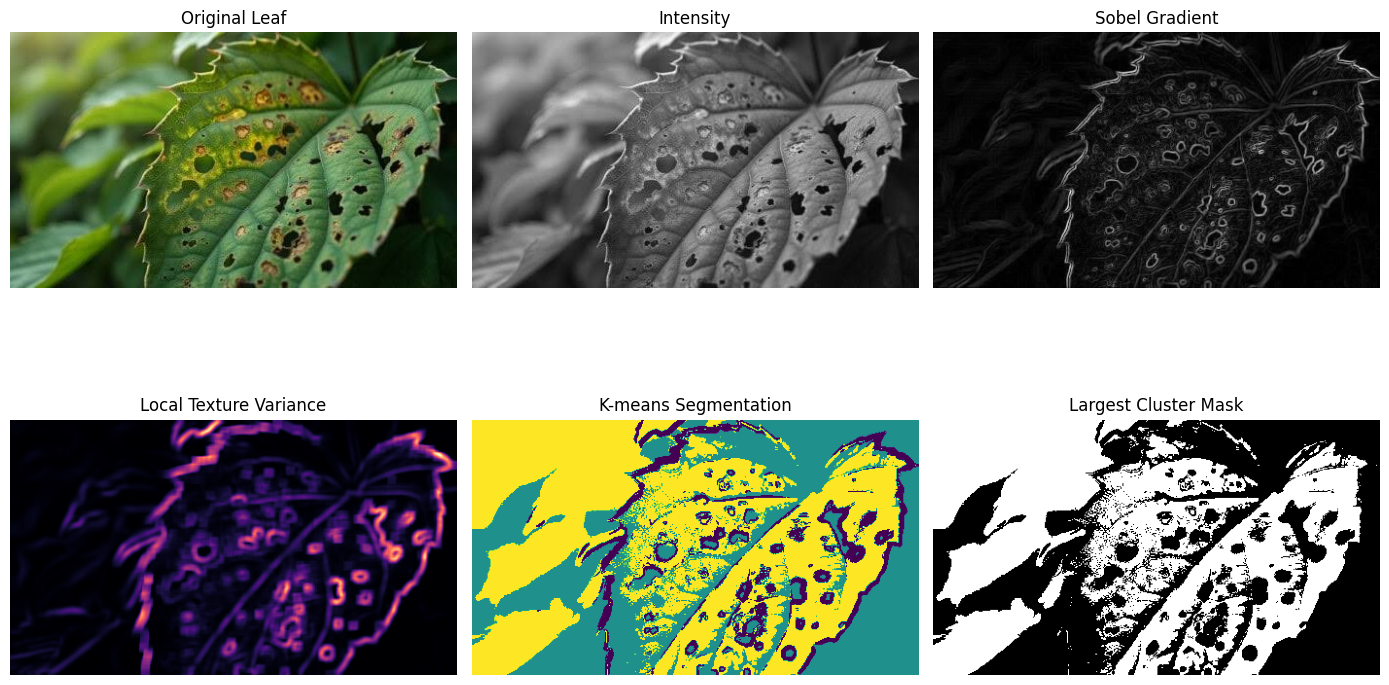

Cluster mean feature values (intensity, gradient, variance):
Cluster 0: [0.37262875 0.27214995 0.37935326]
Cluster 1: [0.1846181  0.03791183 0.04180606]
Cluster 2: [0.47381836 0.0645582  0.0609255 ]

Analysis:
Intensity helps distinguish lesions when their brightness differs from healthy tissue.
Gradient magnitude highlights lesion boundaries but may also detect veins and shadows.
Local variance captures texture differences but can respond to noise and leaf veins.
K-means groups similar features; it does not automatically identify diseased tissue.
A ground-truth disease mask is needed to measure misclassification rates objectively.


In [2]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

image = cv2.imread("plant_leaf_disease.jpg")
if image is None:
    raise FileNotFoundError("Place plant_leaf_disease.jpg in the notebook folder.")

rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

intensity = gray.astype(np.float32) / 255.0

gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
gradient = cv2.magnitude(gx, gy)
gradient /= gradient.max() + 1e-8

g = gray.astype(np.float32)
mean = cv2.blur(g, (9, 9))
mean_sq = cv2.blur(g * g, (9, 9))
variance = np.maximum(mean_sq - mean * mean, 0)
variance /= variance.max() + 1e-8

features = np.stack([intensity, gradient, variance], axis=-1)
h, w = gray.shape

X = StandardScaler().fit_transform(features.reshape(-1, 3))

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10,
    algorithm="lloyd"
)
labels = kmeans.fit_predict(X).reshape(h, w)

fig, ax = plt.subplots(2, 3, figsize=(14, 9))

ax[0, 0].imshow(rgb)
ax[0, 0].set_title("Original Leaf")

ax[0, 1].imshow(intensity, cmap="gray")
ax[0, 1].set_title("Intensity")

ax[0, 2].imshow(gradient, cmap="gray")
ax[0, 2].set_title("Sobel Gradient")

ax[1, 0].imshow(variance, cmap="magma")
ax[1, 0].set_title("Local Texture Variance")

ax[1, 1].imshow(labels, cmap="viridis")
ax[1, 1].set_title("K-means Segmentation")

largest_cluster = np.argmax(np.bincount(labels.ravel()))
ax[1, 2].imshow(labels == largest_cluster, cmap="gray")
ax[1, 2].set_title("Largest Cluster Mask")

for a in ax.ravel():
    a.axis("off")

plt.tight_layout()
plt.show()

print("Cluster mean feature values (intensity, gradient, variance):")
for k in range(3):
    print(f"Cluster {k}:", features[labels == k].mean(axis=0))

print("\nAnalysis:")
print("Intensity helps distinguish lesions when their brightness differs from healthy tissue.")
print("Gradient magnitude highlights lesion boundaries but may also detect veins and shadows.")
print("Local variance captures texture differences but can respond to noise and leaf veins.")
print("K-means groups similar features; it does not automatically identify diseased tissue.")
print("A ground-truth disease mask is needed to measure misclassification rates objectively.")